<a href="https://colab.research.google.com/github/wadeea23/doodle_search_groups/blob/main/doodleDex_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 1: Get the Doodles**

In [1]:
urls = ["https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/apple.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/banana.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/strawberry.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/watermelon.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/blackberry.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/blueberry.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/grapes.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/pear.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/pineapple.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/carrot.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/peas.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/broccoli.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/onion.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/potato.npy",
        "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/peanut.npy"]


In [2]:
import os
import pandas as pd
import urllib.request
import urllib.parse
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
os.makedirs("./data", exist_ok=True)
for url in urls:
    name = urllib.parse.urlsplit(url).path.split("/")[-1]
    urllib.request.urlretrieve(url, f"./data/{name}")
    print(f"{name} downloaded")

apple.npy downloaded
banana.npy downloaded
strawberry.npy downloaded
watermelon.npy downloaded
blackberry.npy downloaded
blueberry.npy downloaded
grapes.npy downloaded
pear.npy downloaded
pineapple.npy downloaded
carrot.npy downloaded
peas.npy downloaded
broccoli.npy downloaded
onion.npy downloaded
potato.npy downloaded
peanut.npy downloaded


In [4]:
data = np.load("./data/apple.npy", mmap_mode="r")
print(data.shape)

rng = np.random.default_rng(42)
idx = np.sort(rng.choice(len(data), size=500, replace=False))
sample = data[idx]
print(sample.shape)

(144722, 784)
(500, 784)


In [5]:
sample.reshape(500, 28,28,1)

array([[[[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        ...,

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]]],


       [[[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        ...,

        [[0],
         [0],
         [0],
         ...,
         [0],


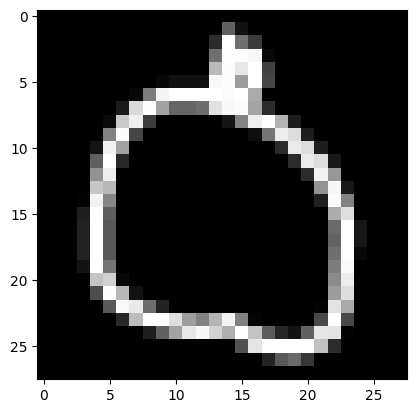

In [6]:
plt.imshow(sample[0].reshape(28,28,1), cmap="gray")

In [7]:
rng = np.random.default_rng(42)
samples = {}

for url in urls:
    name = urllib.parse.urlsplit(url).path.split("/")[-1]

    data = np.load(f"./data/{name}", mmap_mode="r")
    print(name, data.shape)

    idx = np.sort(rng.choice(len(data), size=500, replace=False))
    sample = data[idx]
    print(sample.shape)

    samples[name.replace(".npy", "")] = sample

apple.npy (144722, 784)
(500, 784)
banana.npy (307936, 784)
(500, 784)
strawberry.npy (122301, 784)
(500, 784)
watermelon.npy (132939, 784)
(500, 784)
blackberry.npy (128153, 784)
(500, 784)
blueberry.npy (127878, 784)
(500, 784)
grapes.npy (155305, 784)
(500, 784)
pear.npy (116904, 784)
(500, 784)
pineapple.npy (125071, 784)
(500, 784)
carrot.npy (132459, 784)
(500, 784)
peas.npy (161656, 784)
(500, 784)
broccoli.npy (132826, 784)
(500, 784)
onion.npy (132297, 784)
(500, 784)
potato.npy (329204, 784)
(500, 784)
peanut.npy (126626, 784)
(500, 784)


In [8]:
all_images = np.concatenate([samples[c] for c in samples])

print(all_images.shape)

(7500, 784)


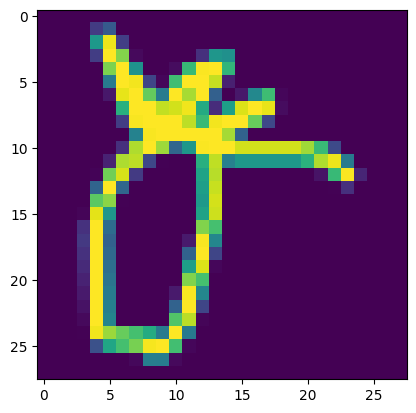

In [9]:
plt.imshow(all_images[4000].reshape(28, 28))

In [10]:
all_images_re = all_images.reshape(7500, 28, 28, 1)

In [11]:
rng = np.random.default_rng(42)

gallery_images = []
query_images = []

for images in samples.values():
    indices = rng.permutation(len(images))

    gallery_images.extend(images[indices[:450]])
    query_images.extend(images[indices[450:]])

gallery_images = np.array(gallery_images)
query_images = np.array(query_images)

print("Gallery:", gallery_images.shape)
print("Query:", query_images.shape)

Gallery: (6750, 784)
Query: (750, 784)


In [12]:
np.savez_compressed(
    "./data/subset.npz",
    gallery_images=gallery_images,
    query_images=query_images
)

data = np.load("./data/subset.npz")

print("Gallery:", data["gallery_images"].shape)
print("Query:", data["query_images"].shape)

Gallery: (6750, 784)
Query: (750, 784)


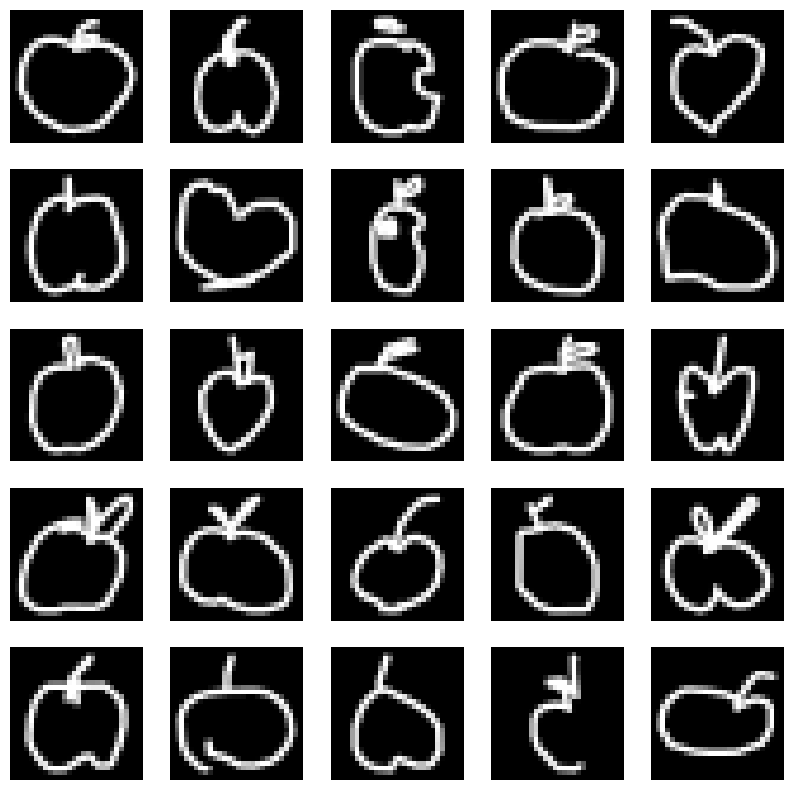

In [13]:
fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(gallery_images[i].reshape(28, 28), cmap="gray")
    ax.axis("off")

plt.show()

# **Task 2: Choose a Model and Build the Index**

In [14]:
from tensorflow.keras.applications import MobileNetV2

backbone = MobileNetV2(
                        weights="imagenet",
                        include_top=False,
                        pooling="avg"
                      )

/tmp/ipykernel_5054/2954441319.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [15]:
backbone.trainable = False
backbone.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, None,      │        864 │ input_layer[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, None,      │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, None,      │          0 │ bn_Conv1[0][0]    │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │          0 │ expanded_conv_de… │
│ (ReLU)              │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, None,      │        512 │ expanded_conv_de… │
│ (Conv2D)            │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, None,      │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, None,      │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, None,      │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, None,      │          0 │ block_1_expand_B… │
│ (ReLU)              │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, None,      │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, None,      │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, None,      │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, None,      │          0 │ block_1_depthwis… │
│ (ReLU)              │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, None,      │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
gallery_embeddings = []

for i in range(0, len(gallery_images), 32):
    images = gallery_images[i:i+32].reshape(-1, 28, 28, 1)

    images = tf.image.resize(images, (224, 224))
    images = tf.image.grayscale_to_rgb(images)
    images = preprocess_input(images.numpy().astype("float32"))

    embeddings = backbone.predict(images)
    gallery_embeddings.append(embeddings)

gallery_embeddings = np.concatenate(gallery_embeddings)

print(gallery_embeddings.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━

In [17]:
os.makedirs("./index", exist_ok=True)

np.save("./index/embeddings.npy", gallery_embeddings)
np.save("./index/gallery_images.npy", gallery_images)

print("Embeddings saved successfully!")

Embeddings saved successfully!


In [18]:
from sklearn.preprocessing import normalize

gallery_embeddings = normalize(gallery_embeddings, norm="l2")

print(np.linalg.norm(gallery_embeddings[:5], axis=1))

[0.9999999  1.         0.99999994 1.         0.99999994]


In [19]:
np.save("./index/embeddings.npy", gallery_embeddings)

print("Normalized embeddings saved!")
print(np.load("./index/embeddings.npy").shape)

Normalized embeddings saved!
(6750, 1280)


# **Task 3: Make Every Query Look Like the Gallery**

In [20]:
from PIL import Image, ImageOps

def preprocess_query(image, background="white"):

    # Handle transparent images (RGBA)
    if image.mode == "RGBA":
        bg = Image.new("RGBA", image.size, background)
        image = Image.alpha_composite(bg, image)

    # Grayscale
    gray = image.convert("L")

    # White strokes on black background
    if np.array(gray).mean() > 127:
        gray = ImageOps.invert(gray)

    # Thresholding
    gray = np.where(np.array(gray) > 150, 255, 0).astype("uint8")
    gray = Image.fromarray(gray)

    # Check for empty image
    if gray.getbbox() is None:
        return None

    # Crop
    gray = gray.crop(gray.getbbox())

    # Add margin
    margin = max(2, int(max(gray.size) * 0.1))
    gray = ImageOps.expand(gray, border=margin, fill=0)

    # Center, pad and resize to 28x28
    return ImageOps.pad(gray, (28, 28), color=0)

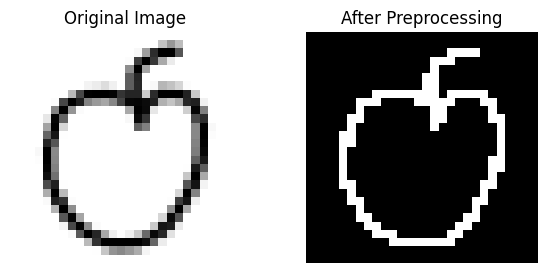

In [21]:
test_image = Image.fromarray(
    query_images[0].reshape(28, 28).astype("uint8")
)

# Simulate a black drawing on a white background
test_image = ImageOps.invert(test_image)

processed = preprocess_query(test_image)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].imshow(test_image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(processed, cmap="gray")
axes[1].set_title("After Preprocessing")

for ax in axes:
    ax.axis("off")

plt.show()

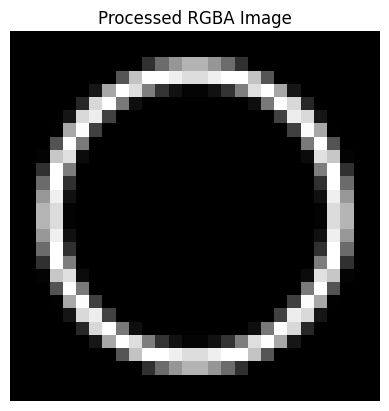

In [22]:
test_rgba = Image.new("RGBA", (200, 200), (0, 0, 0, 0))

from PIL import ImageDraw

draw = ImageDraw.Draw(test_rgba)
draw.ellipse((40, 40, 160, 160), outline="black", width=8)

processed = preprocess_query(test_rgba)

plt.imshow(processed, cmap="gray")
plt.title("Processed RGBA Image")
plt.axis("off")
plt.show()

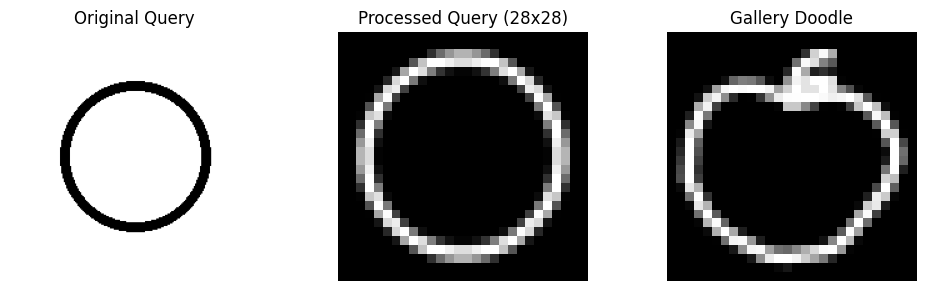

In [23]:
processed = preprocess_query(test_rgba)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

axes[0].imshow(test_rgba)
axes[0].set_title("Original Query")

axes[1].imshow(processed, cmap="gray")
axes[1].set_title("Processed Query (28x28)")

axes[2].imshow(gallery_images[0].reshape(28, 28), cmap="gray")
axes[2].set_title("Gallery Doodle")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
query = query_images[0].reshape(28, 28, 1)

query = tf.image.resize(query, (224, 224))
query = tf.image.grayscale_to_rgb(query)
query = preprocess_input(query.numpy().astype("float32"))
query = np.expand_dims(query, axis=0)

print(query.shape)

(1, 224, 224, 3)


In [25]:
query_embedding = backbone.predict(query)

print(query_embedding.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
(1, 1280)


In [26]:
query_embedding = normalize(query_embedding, norm="l2")

print(np.linalg.norm(query_embedding))

1.0


In [27]:
similarities = cosine_similarity(query_embedding, gallery_embeddings)

print(similarities.shape)

(1, 6750)


# **Task 4: Evaluating the Search Engine**

In [28]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=25, algorithm='brute', metric='cosine')
neighbors.fit(gallery_embeddings)

NearestNeighbors(algorithm='brute', metric='cosine', n_neighbors=25)

In [29]:
distances, indices = neighbors.kneighbors(query_embedding)

print(indices.shape)
print(indices[0])

(1, 25)
[ 239  272  305  143  147  376  339   65  329  393 1012 2332 2654  114
 2528  230  375   37  399   72  188  131 2685  352 2604]


In [30]:
def plot_image_search_results(query_image, matched_images, scores):

    total_images = len(matched_images) + 1

    plt.figure(figsize=(12, 12))

    # Query Image
    plt.subplot(6, 5, 1)
    plt.imshow(query_image.reshape(28, 28), cmap="gray")
    plt.title("Query Image", fontweight="bold")
    plt.axis("off")

    # Retrieved Images
    for i, (image, score) in enumerate(zip(matched_images, scores)):
        plt.subplot(6, 5, i + 2)
        plt.imshow(image.reshape(28, 28), cmap="gray")
        plt.title(f"Score: { 1- score:.2f}", fontsize=10)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

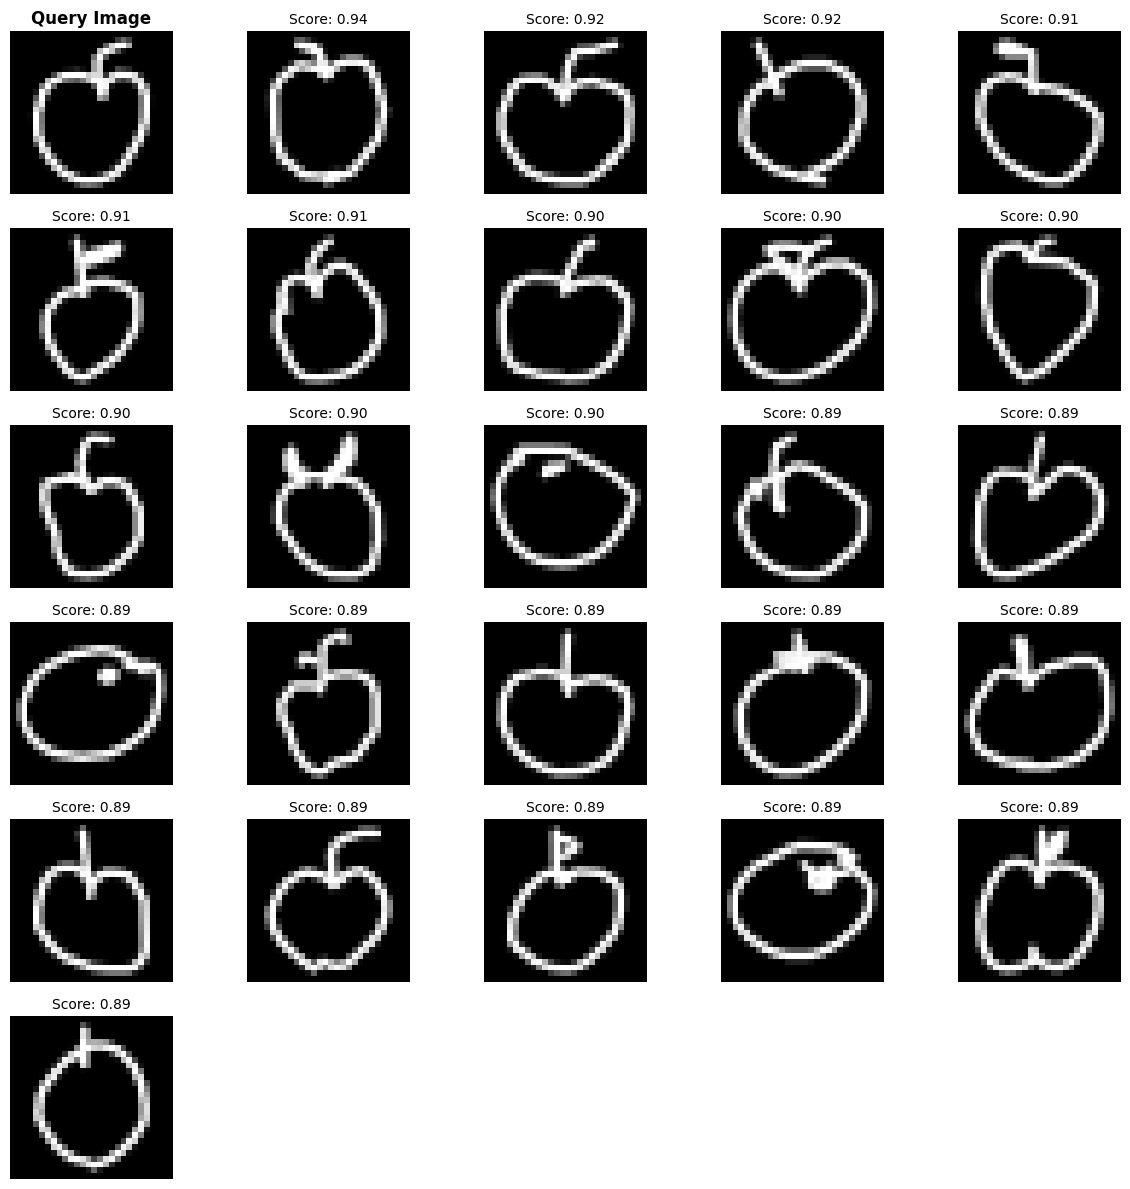

In [31]:
plot_image_search_results(
    query_images[0],
    gallery_images[indices[0]],
    distances[0]
)

In [32]:
data = np.load("./data/subset.npz")

print(data.files)

['gallery_images', 'query_images']
